# DropoutIA — Modélisation : niveau de risque (4 classes)

Même démarche que pour le décrochage (notebook 3), appliquée cette fois au
jeu de données **niveau de risque** (`id_niveauRisqueInit`, 4 catégories :
1 = très faible à 4 = sévère, selon la nomenclature officielle du MEN).

Comme il y a 4 classes ici (pas 2), la fonction `comparer_modeles` bascule
automatiquement sur un recall **macro** (moyenne du recall sur les 4
classes à égalité) plutôt que sur le recall d'une seule classe — voir
`src/modelisation.py`.

## 1. Chargement des données nettoyées

In [1]:
import pandas as pd
import sys, os

chemin_src = os.path.abspath("../src")
sys.path.append(chemin_src)
import modelisation

df = pd.read_csv("../data/processed/donnees_risque_clean.csv")
print(df.shape)
df.head()

(10000, 11)


,id_Genre,Nefstat,NbrAbsence,NbrRedoublement,MoyenneNotes,CD_REG,CD_PROV,CD_MIL,id_niveauRisqueInit,NbrAbsence_manquant,age
0,1,14,1.0,2,8.188333,12,391,1,3,1,18
1,1,14,1.0,1,8.811667,12,391,1,2,1,17
2,1,14,1.0,2,10.228333,12,391,1,3,1,17
3,2,14,1.0,2,10.595000,12,391,1,3,1,16
4,1,14,1.0,2,8.970000,12,391,1,3,1,17


## 2. Préparation train/test

Rappel : `stratify=y` garantit que les 4 niveaux de risque gardent la même
proportion dans le train et le test, malgré leur fort déséquilibre
(niveau 4 = seulement 3% des élèves).

In [2]:
X_train, X_test, y_train, y_test = modelisation.preparer_donnees(df, colonne_cible="id_niveauRisqueInit")
print("Train :", X_train.shape, "| Test :", X_test.shape)
print("\nRepartition dans train :")
print(y_train.value_counts(normalize=True).sort_index() * 100)
print("\nRepartition dans test :")
print(y_test.value_counts(normalize=True).sort_index() * 100)

Train : (8000, 10) | Test : (2000, 10)

Repartition dans train :
id_niveauRisqueInit
1    70.5125
2    18.6000
3     7.8500
4     3.0375
Name: proportion, dtype: float64

Repartition dans test :
id_niveauRisqueInit
1    70.50
2    18.60
3     7.85
4     3.05
Name: proportion, dtype: float64


## 3. Comparaison des 4 modèles

Avec 4 classes, on regarde le **recall macro** (moyenne du recall sur
chacune des 4 classes, à égalité) plutôt que le recall d'une seule classe
comme pour le décrochage. C'est important ici : sans ça, le score serait
dominé par la classe 1 (majoritaire), et on pourrait rater un mauvais
recall sur la classe 4 (sévère) — pourtant la plus critique à détecter.

In [3]:
tableau_resultats, modeles_entraines = modelisation.comparer_modeles(X_train, X_test, y_train, y_test)
tableau_resultats

c:\Users\J.P.M\Desktop\dropoutia\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,modele,accuracy,precision_globale,recall_global,f1_global,recall_classe_1
0,Gradient Boosting,0.961,0.965,0.961,0.961,0.981
1,Arbre de decision,0.950,0.957,0.950,0.952,0.976
2,Random Forest,0.963,0.965,0.963,0.963,0.975
3,Regression logistique,0.898,0.914,0.898,0.902,0.925


## 4. Analyse détaillée du meilleur modèle

Le rapport détaillé va afficher le recall **par niveau de risque**
(1 à 4) séparément — c'est ici qu'on vérifie si le modèle détecte bien
les cas les plus graves (niveau 4), pas juste les cas globaux.

In [4]:
meilleur_nom = tableau_resultats.iloc[0]['modele']
print("Meilleur modele :", meilleur_nom)

meilleur_modele = modeles_entraines[meilleur_nom]
modelisation.rapport_detaille(meilleur_modele, X_test, y_test)

Meilleur modele : Gradient Boosting
              precision    recall  f1-score   support

           1       0.99      0.95      0.97      1410
           2       0.84      0.97      0.90       372
           3       1.00      1.00      1.00       157
           4       1.00      1.00      1.00        61

    accuracy                           0.96      2000
   macro avg       0.96      0.98      0.97      2000
weighted avg       0.96      0.96      0.96      2000

Matrice de confusion :
[[1342   68    0    0]
 [  11  361    0    0]
 [   0    0  157    0]
 [   0    0    0   61]]


## 5. Importance des caractéristiques

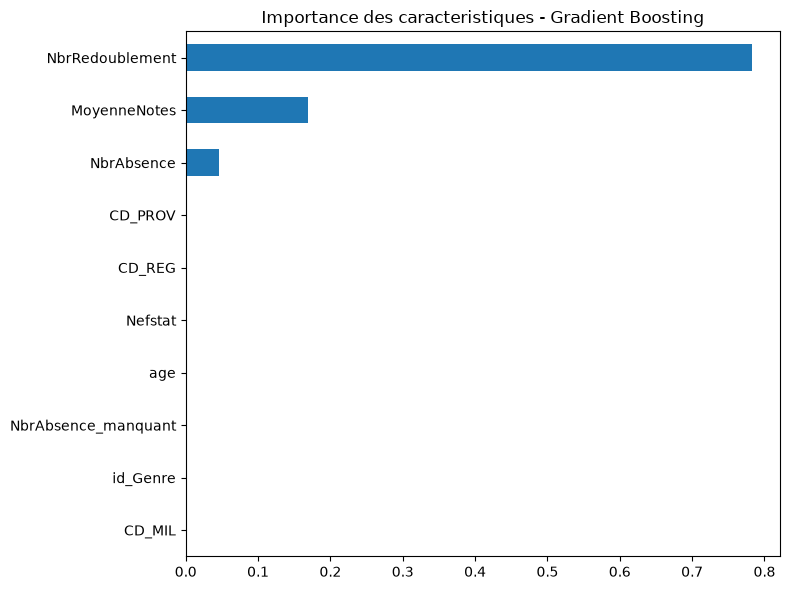

In [5]:
import matplotlib.pyplot as plt

if hasattr(meilleur_modele, 'feature_importances_'):
    importances = pd.Series(meilleur_modele.feature_importances_, index=X_train.columns)
    importances.sort_values(ascending=True).plot(kind='barh', figsize=(8,6))
    plt.title(f"Importance des caracteristiques - {meilleur_nom}")
    plt.tight_layout()
    plt.show()
else:
    print("Ce modele n'a pas d'attribut feature_importances_.")

## 6. Sauvegarde du meilleur modèle

In [6]:
import joblib
joblib.dump(meilleur_modele, "../models/modele_risque.pkl")
print("Modele sauvegarde :", meilleur_nom)

Modele sauvegarde : Gradient Boosting


In [7]:
df.groupby('id_niveauRisqueInit')[['NbrAbsence', 'NbrRedoublement', 'MoyenneNotes']].agg(['min', 'max'])

NbrAbsence       NbrRedoublement     MoyenneNotes  \
                           min   max             min max          min   
id_niveauRisqueInit                                                     
1                          0.0  67.0               0   1          0.0   
2                          0.0  54.0               0   2          0.0   
3                          0.0  46.0               2   3          0.0   
4                          0.0  34.0               3   5          0.0   

                                
                           max  
id_niveauRisqueInit             
1                    19.925000  
2                    17.885000  
3                    15.573333  
4                    13.123333